## Step 1: Import libraries and load MNIST

In [1]:
# Import required libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Display dataset dimensions
print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


## Step 2: Display 9 random handwritten digits

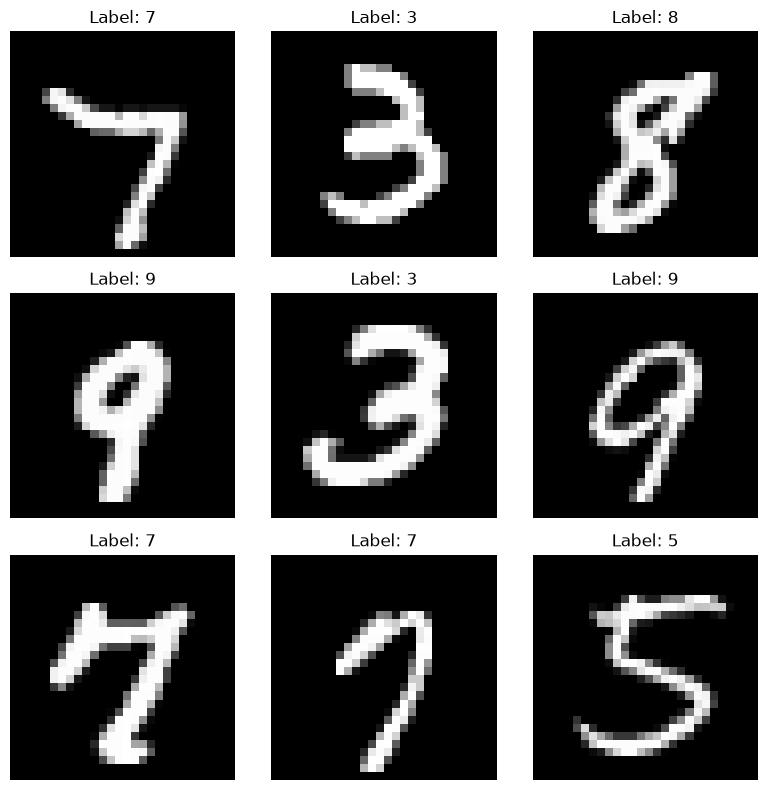

In [2]:
# Set random seed for reproducibility
np.random.seed(42)

# Select 9 random images
random_indices = np.random.choice(len(X_train), 9, replace=False)

# Create a 3x3 visualization
plt.figure(figsize=(8, 8))

for i, index in enumerate(random_indices):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[index], cmap="gray")
    plt.title(f"Label: {y_train[index]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 3: Data Preprocessing

## 3.1 Normalize the image data

In [3]:
# Normalize pixel values to the range [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Check normalized pixel values
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 3.2 One-hot encode the labels

In [4]:
# Convert labels into one-hot encoded vectors
y_train_encoded = to_categorical(y_train, num_classes=10)
y_test_encoded = to_categorical(y_test, num_classes=10)

# Display original and encoded labels
print("Original label:", y_train[0])
print("Encoded label:", y_train_encoded[0])

print("Training labels shape:", y_train_encoded.shape)
print("Testing labels shape:", y_test_encoded.shape)

Original label: 5
Encoded label: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
Training labels shape: (60000, 10)
Testing labels shape: (10000, 10)


## 3.3 Confirm preprocessing

In [5]:
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

print("Training labels:", y_train_encoded.shape)
print("Testing labels:", y_test_encoded.shape)

print("Pixel range:", X_train.min(), "to", X_train.max())

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Training labels: (60000, 10)
Testing labels: (10000, 10)
Pixel range: 0.0 to 1.0


## Step 4: Build the Artificial Neural Network (ANN)

## 4.1 Import the required Keras components

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout

## 4.2 Build the model

In [7]:
# Initialize the ANN model
model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation="relu"),

    Dropout(0.3),

    Dense(64, activation="relu"),

    Dense(10, activation="softmax")
])

# Display model architecture
model.summary()

c:\Users\Admin\Documents\mnist-ann-handwritten-digit-classification\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Step 5: Compile the ANN Model

In [8]:
# Compile the ANN model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


## Step 6: Configure Callbacks

In [9]:
from tensorflow.keras.callbacks import EarlyStopping, TensorBoard
from datetime import datetime

# Create a unique TensorBoard log directory
log_dir = "logs/fit/" + datetime.now().strftime("%Y%m%d-%H%M%S")

# Configure Early Stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Configure TensorBoard
tensorboard_callback = TensorBoard(
    log_dir=log_dir,
    histogram_freq=1
)

print("Callbacks configured successfully!")

Callbacks configured successfully!


## Step 7: Train the ANN Model

In [10]:
# Train the ANN model
history = model.fit(
    X_train,
    y_train_encoded,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[
        early_stopping,
        tensorboard_callback
    ],
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8667 - loss: 0.4494 - val_accuracy: 0.9587 - val_loss: 0.1503
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9409 - loss: 0.2013 - val_accuracy: 0.9690 - val_loss: 0.1081
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9546 - loss: 0.1520 - val_accuracy: 0.9718 - val_loss: 0.0926
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9616 - loss: 0.1266 - val_accuracy: 0.9770 - val_loss: 0.0801
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9659 - loss: 0.1093 - val_accuracy: 0.9795 - val_loss: 0.0748
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9695 - loss: 0.0971 - val_accuracy: 0.9778 - val_loss: 0.0720
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9729 - loss: 0.0875 - val_accuracy: 0.9795 - val_loss: 0.0693
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9732 - loss: 0.0823 - val_accuracy: 0.

What do these results tell us?
1. Accuracy improved: Training accuracy increased from 86.67% to 97.71%.
2. Loss decreased: Training loss dropped from 0.4494 to 0.0705.
3. Good generalization: Validation accuracy reached 97.95%, suggesting the model performs well on data it did not train on.
4. No obvious severe overfitting: Training and validation performance remain close.

One interesting observation: validation accuracy is slightly higher than training accuracy. This can happen because dropout is active during training but disabled during validation.

## Step 8: Visualize Training and Validation Performance

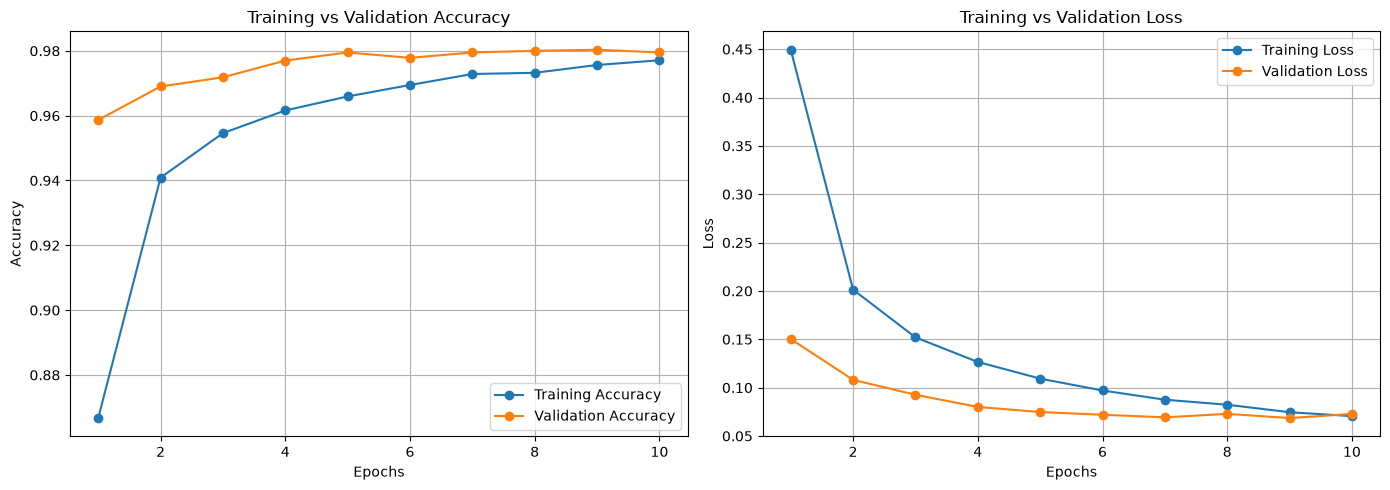

In [11]:
# Extract training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

# Create visualizations
plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracy, marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, marker="o", label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Interpretation 

The learning curves demonstrate that the ANN successfully learned patterns from the MNIST dataset. Training accuracy increased progressively while training and validation losses decreased. The relatively small difference between training and validation performance suggests that the model generalizes well to unseen data, with no clear evidence of severe overfitting.

## Step 9: Evaluate the Model on Test Data

In [12]:
# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9765 - loss: 0.0788
Test Loss: 0.0788
Test Accuracy: 0.9765
Test Accuracy (%): 97.65%


This means the model correctly classified approximately 9,765 out of 10,000 test images.

## Step 10: Generate predictions

In [13]:
# Generate predictions for the test dataset
y_pred_prob = model.predict(X_test)

# Convert probabilities into predicted digit labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Actual digit labels
y_true = y_test

# Display the first 10 predictions alongside actual labels
print("Predicted labels:", y_pred[:10])
print("Actual labels:   ", y_true[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predicted labels: [7 2 1 0 4 1 4 9 6 9]
Actual labels:    [7 2 1 0 4 1 4 9 5 9]


## Step 11: Create the confusion matrix

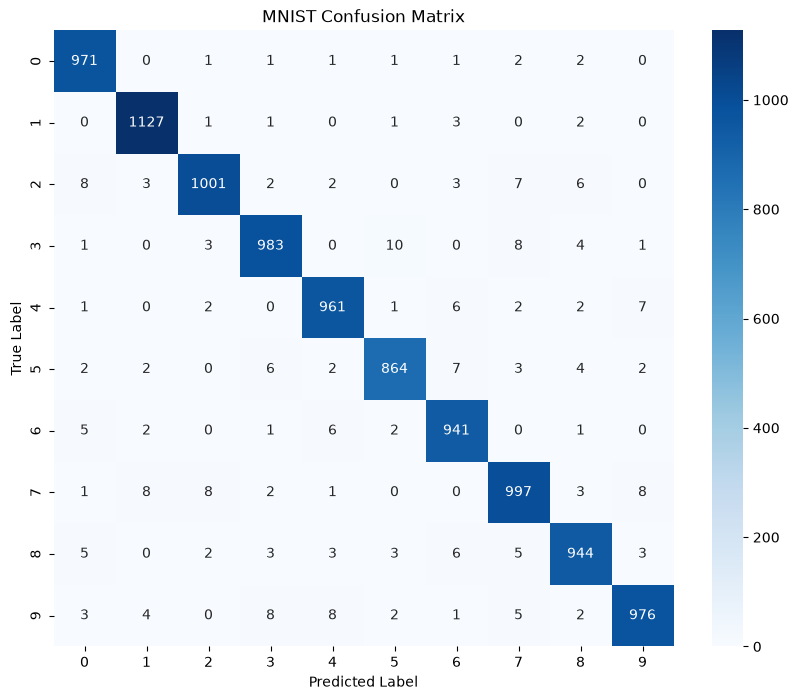

In [14]:
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Visualize the confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MNIST Confusion Matrix")
plt.show()

## Step 12: Generate the classification report
The classification report evaluates how well your model recognizes each digit from 0 to 9.

In [15]:
from sklearn.metrics import classification_report

# Generate the classification report
report = classification_report(
    y_true,
    y_pred,
    digits=4
)

print(report)

              precision    recall  f1-score   support

           0     0.9739    0.9908    0.9823       980
           1     0.9834    0.9930    0.9882      1135
           2     0.9833    0.9700    0.9766      1032
           3     0.9762    0.9733    0.9747      1010
           4     0.9766    0.9786    0.9776       982
           5     0.9774    0.9686    0.9730       892
           6     0.9721    0.9823    0.9772       958
           7     0.9689    0.9698    0.9694      1028
           8     0.9732    0.9692    0.9712       974
           9     0.9789    0.9673    0.9731      1009

    accuracy                         0.9765     10000
   macro avg     0.9764    0.9763    0.9763     10000
weighted avg     0.9765    0.9765    0.9765     10000



Interpretion

- Accuracy: 97.65% — the model correctly classified 97.65% of test images.
- Macro F1-score: 97.63% — strong, balanced performance across all ten digits.
- Weighted F1-score: 97.65% — strong overall performance, accounting for the number of images in each class.
- Best-performing digit: Digit 1, with an F1-score of 98.82%.
- Lowest-performing digit: Digit 7, with an F1-score of 96.94%.

The model performs well across all classes, with relatively small differences between their scores.

## Step 13: Save your trained model

In [16]:
# Save the trained model
model.save("../models/mnist_ann_model.keras")

print("Model saved successfully!")

Model saved successfully!


## Step 14: View your TensorBoard training logs

## Step 14.1: Check the correct log directory

In [21]:
from pathlib import Path

log_path = Path("logs/fit")

print("Log folder exists:", log_path.exists())
print("Log files:", list(log_path.rglob("*")))

Log folder exists: True
Log files: [WindowsPath('logs/fit/20261111-194843'), WindowsPath('logs/fit/20261111-195203'), WindowsPath('logs/fit/20261111-194843/train'), WindowsPath('logs/fit/20261111-195203/train'), WindowsPath('logs/fit/20261111-195203/validation'), WindowsPath('logs/fit/20261111-194843/train/events.out.tfevents.1794415769.DESKTOP-1CTJSL3.22784.0.v2'), WindowsPath('logs/fit/20261111-195203/train/events.out.tfevents.1794415923.DESKTOP-1CTJSL3.23436.0.v2'), WindowsPath('logs/fit/20261111-195203/validation/events.out.tfevents.1794415928.DESKTOP-1CTJSL3.23436.1.v2')]


In [ ]:
%load_ext tensorboard
%tensorboard --logdir ../logs/fit

Interpretation

TensorBoard was used to monitor the Artificial Neural Network's training process. The training and validation accuracy increased progressively, while both training and validation loss decreased over the 10 epochs. The final training accuracy was 97.71%, compared with a validation accuracy of 97.95%. The relatively small performance gap suggests that the model learned effectively and generalizes well to unseen data. No clear evidence of severe overfitting was observed.
